![Python Banner](../../Image/05_04_doubleML.png)


# 4.3 Double ML for Difference-in-Differences: Panel Data

**Double machine learning for difference-in-differences** keeps the identification logic of DiD and lets the nuisance functions be flexible. Classic two-way fixed effects assume

$$Y_{it} = \alpha_i + \gamma_t + \theta (D_{it} \times \text{Post}_t) + \varepsilon_{it}.$$

With a first-differenced outcome the partially linear version is

$$\Delta Y_{it} = \theta D_{it} + g(X_{it}) + \zeta_{it},$$

where $g$ is cross-fit rather than forced to be linear.


## Overview

| Step | Component | Purpose |
|------|-----------|---------|
| 1 | Nuisance estimation | Propensity $\hat{e}(X) = P(D=1\mid X)$ and control regression $\hat{\ell}(X) = E[\Delta Y \mid D=0, X]$ |
| 2 | Cross-fitting | Train on $K-1$ folds, predict on the held-out fold |
| 3 | Orthogonal score | $\psi_i = \big(\frac{D_i}{\bar{p}} - \frac{(1-D_i)\hat{e}(X_i)}{\bar{p}(1-\hat{e}(X_i))}\big)(\Delta Y_i - \hat{\ell}(X_i))$ |
| 4 | Final estimation | $\hat{\theta} = n^{-1}\sum_i \psi_i$, with an influence-function standard error |

| Challenge | Linear DiD | DML-DiD |
|-----------|------------|---------|
| Many controls | OLS is noisy or infeasible when $p$ is large | ML fits the nuisances |
| Nonlinear confounding | A linear $g(X)$ is misspecified | Forests and boosting approximate $g$ |
| Inference | Valid under correct linear specification | Valid if the nuisances converge and the score is orthogonal |

The group-time estimand $\mathrm{ATT}(g,t)$ is the effect at calendar time $t$ for the cohort first treated at $g$, using not-yet-treated and never-treated units as controls (Callaway and Sant'Anna, 2021). The score above is the doubly robust DiD score of Sant'Anna and Zhao (2020) applied to $\Delta Y$.


## Implementation in Python

Each group-time cell is a 2×2 difference in differences on the first-differenced outcome. Three nuisance pairs are compared:

| Wrapper | Outcome nuisance | Propensity |
|---------|------------------|------------|
| linear | ridge | logistic regression |
| random forest | random forest | random forest |
| gradient boosting | gradient boosting | gradient boosting |

`DifferenceInDifferences` from PyCausalML is the unadjusted two-period benchmark on one cohort. Aggregation is a simple average of the group-time estimates. SHAP is applied to a `LinearDML` fit on a single first-differenced slice, which describes CATE heterogeneity inside that slice.


## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
data_dir = root / "Data"
if not data_dir.is_dir():
    raise FileNotFoundError(
        "The Data directory was not found. It should sit next to pyproject.toml."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Data directory:", data_dir)


PyCausalML ready.
Data directory: /home/zia207/Github/PyCausalML/Data


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    mean_squared_error,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pycausalml import (
    CausalForestDML,
    InteractiveRegressionDML,
    KernelDML,
    LinearDML,
    NonParamDML,
    PartiallyLinearDML,
    SparseLinearDML,
    explain_cate,
)
from pycausalml.interpretation import plot_cate_hist

plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")

from pycausalml import DifferenceInDifferences


Imported PyCausalML


In [3]:
def _classifier(kind, seed):
    if kind == "logit":
        return LogisticRegression(max_iter=400)
    if kind == "rf":
        return RandomForestClassifier(
            n_estimators=40, max_depth=4, min_samples_leaf=5, random_state=seed, n_jobs=1,
        )
    return GradientBoostingClassifier(
        n_estimators=30, max_depth=2, learning_rate=0.08, random_state=seed,
    )


def _regressor(kind, seed):
    if kind == "ridge":
        return Ridge(alpha=1.0)
    if kind == "rf":
        return RandomForestRegressor(
            n_estimators=40, max_depth=4, min_samples_leaf=5, random_state=seed, n_jobs=1,
        )
    return GradientBoostingRegressor(
        n_estimators=30, max_depth=2, learning_rate=0.08, random_state=seed,
    )


def dr_att(X, d, dy, learner="linear", seed=0, n_splits=2):
    """Doubly robust ATT for a first-differenced 2×2 comparison."""
    d = np.asarray(d, dtype=int)
    dy = np.asarray(dy, dtype=float)
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    n = len(d)
    e_hat = np.full(n, float(d.mean()))
    mu0 = np.full(n, float(dy[d == 0].mean()) if np.any(d == 0) else 0.0)
    kind_c = {"linear": "logit", "rf": "rf", "gbr": "gbr"}[learner]
    kind_r = {"linear": "ridge", "rf": "rf", "gbr": "gbr"}[learner]
    splitter = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for fold, (tr, te) in enumerate(splitter.split(X)):
        if len(np.unique(d[tr])) < 2 or np.sum(d[tr] == 0) < 8:
            continue
        clf = _classifier(kind_c, seed + fold)
        clf.fit(X[tr], d[tr])
        e_hat[te] = clf.predict_proba(X[te])[:, 1]
        reg = _regressor(kind_r, seed + fold)
        ctrl = tr[d[tr] == 0]
        reg.fit(X[ctrl], dy[ctrl])
        mu0[te] = reg.predict(X[te])
    e_hat = np.clip(e_hat, 0.05, 0.95)
    p_hat = float(np.mean(d))
    psi = (d / p_hat - (1 - d) * e_hat / (p_hat * (1 - e_hat))) * (dy - mu0)
    theta = float(np.mean(psi))
    se = float(np.std(psi, ddof=1) / np.sqrt(n))
    rmse = float(np.sqrt(np.mean((dy[d == 0] - mu0[d == 0]) ** 2)))
    acc = float(np.mean((e_hat >= 0.5).astype(int) == d))
    return {"att": theta, "se": se, "rmse_mu0": rmse, "propensity_acc": acc}


def simulate_panel(n_units=700, seed=0):
    rng = np.random.default_rng(seed)
    cohort = rng.choice([0, 2, 3, 4], size=n_units, p=[0.45, 0.2, 0.2, 0.15])
    x = rng.normal(size=(n_units, 2))
    rows = []
    for period in (1, 2, 3, 4):
        treated_now = ((cohort > 0) & (period >= cohort)).astype(float)
        exposure = np.where(treated_now == 1, period - cohort, 0)
        outcome = (
            0.4 * x[:, 0]
            + 0.15 * period
            + treated_now * (1.0 + 0.4 * exposure)
            + 0.25 * x[:, 1] * treated_now
            + rng.normal(scale=0.45, size=n_units)
        )
        rows.append(pd.DataFrame({
            "id": np.arange(n_units),
            "period": period,
            "G": cohort,
            "Y": outcome,
            "treat": treated_now.astype(int),
            "x1": x[:, 0],
            "x2": x[:, 1],
        }))
    return pd.concat(rows, ignore_index=True)


print("DiD helpers ready")


DiD helpers ready


## Part A: Simulated Data

Four periods and staggered adoption. The effect equals $1 + 0.4 \times \text{exposure}$ plus a small $x_2$ interaction, so the cohort-time target, averaging over $x_2$, is about $1 + 0.4(t-g)$. Units are stored in long format.


In [4]:
panel = simulate_panel()
print(panel.groupby(["G", "period"]).size().unstack(fill_value=0))
panel.head()


period    1    2    3    4
G                         
0       295  295  295  295
2       142  142  142  142
3       152  152  152  152
4       111  111  111  111


,id,period,G,Y,treat,x1,x2
0,0,1,2,0.368434,0,1.304508,0.151275
1,1,1,0,0.786341,0,0.850301,-0.605664
2,2,1,0,1.012178,0,1.376725,0.345278
3,3,1,0,0.753181,0,0.481246,0.548729
4,4,1,3,0.753199,0,-0.797009,-1.865721


| Variable | Role |
|---|---|
| `G` | First period treated (0 = never) |
| `period` | Time |
| `Y` | Outcome |
| `treat` | 1 if the unit is treated in this period |
| `x1`, `x2` | Covariates |
| `id` | Unit identifier |

### Benchmark: two-period DiD

`DifferenceInDifferences` fits $Y = a + b\,\text{treated} + c\,\text{post} + \tau\,\text{treated}\times\text{post}$ on the never-treated units and the cohort first treated in period 2, using periods 1 and 2. The target for that cell is about 1.


In [5]:
sub = panel[panel["G"].isin([0, 2]) & panel["period"].isin([1, 2])].copy()
did = DifferenceInDifferences(n_boot=80, random_state=0)
did.fit(
    sub["Y"].to_numpy(),
    (sub["G"] == 2).astype(float).to_numpy(),
    (sub["period"] == 2).astype(float).to_numpy(),
)
print(did.summary())


{'estimate': 1.0420090240872752, 'ci_lower': 0.8551152983045504, 'ci_upper': 1.210054659144033, 'posterior_mean': 1.0545496878221035}


### Group-time ATT with three nuisance learners

For each cohort $g \in \{2,3,4\}$ and time $t \ge g$, the pre-period is $g-1$ and the control group is never-treated units. The outcome in the score is $\Delta Y = Y_t - Y_{g-1}$.


In [6]:
def group_time_table(frame, id_col, time_col, cohort_col, y_col, x_cols, learner):
    cohorts = sorted(g for g in frame[cohort_col].unique() if g > 0)
    rows = []
    for g in cohorts:
        pre = int(g) - 1
        for t in sorted(frame[time_col].unique()):
            if t < g or pre not in set(frame[time_col]):
                continue
            post = frame[frame[time_col] == t][[id_col, y_col, cohort_col, *x_cols]]
            base = frame[frame[time_col] == pre][[id_col, y_col]].rename(columns={y_col: "y_pre"})
            merged = post.merge(base, on=id_col)
            treated = merged[cohort_col] == g
            control = merged[cohort_col] == 0
            sample = merged[treated | control]
            if sample[cohort_col].eq(g).sum() < 15 or sample[cohort_col].eq(0).sum() < 15:
                continue
            result = dr_att(
                sample[x_cols].to_numpy(),
                (sample[cohort_col] == g).astype(int).to_numpy(),
                (sample[y_col] - sample["y_pre"]).to_numpy(),
                learner=learner,
                seed=int(g) * 10 + int(t),
            )
            result.update({"G": int(g), "time": int(t), "learner": learner, "target": 1.0 + 0.4 * (int(t) - int(g))})
            rows.append(result)
    return pd.DataFrame(rows)


tables = [group_time_table(panel, "id", "period", "G", "Y", ["x1", "x2"], learner) for learner in ("linear", "rf", "gbr")]
att_a = pd.concat(tables, ignore_index=True)
att_a.round(3)


,att,se,rmse_mu0,propensity_acc,G,time,learner,target
0,1.072,0.104,0.686,0.675,2,2,linear,1.0
1,1.338,0.117,0.592,0.675,2,3,linear,1.4
2,1.779,0.142,0.637,0.675,2,4,linear,1.8
3,0.979,0.096,0.672,0.660,3,3,linear,1.0
4,1.345,0.111,0.631,0.653,3,4,linear,1.4
5,0.989,0.108,0.647,0.727,4,4,linear,1.0
6,1.183,0.121,0.708,0.618,2,2,rf,1.0
7,1.327,0.120,0.619,0.670,2,3,rf,1.4
8,1.833,0.149,0.643,0.648,2,4,rf,1.8
9,0.987,0.098,0.677,0.653,3,3,rf,1.0


On this near-linear design the linear nuisance usually tracks the target closely. Random forests and gradient boosting add flexibility; their standard errors are often a little larger.


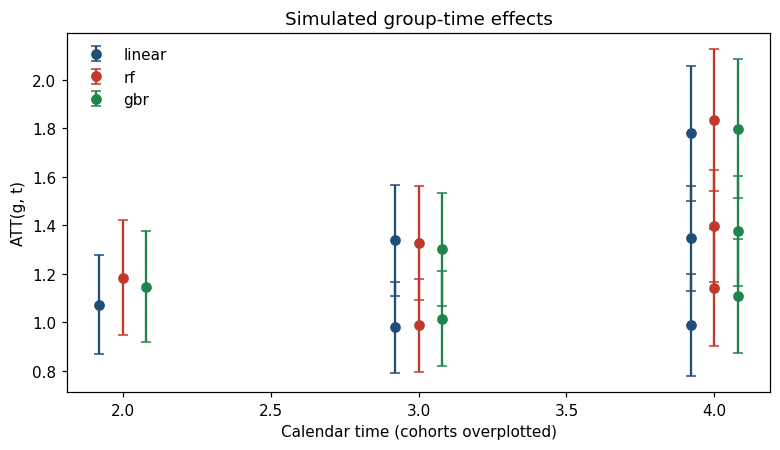

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for learner, color in (("linear", "#1F4E79"), ("rf", "#C0392B"), ("gbr", "#1E8449")):
    part = att_a[att_a["learner"] == learner]
    ax.errorbar(
        part["time"] + {"linear": -0.08, "rf": 0.0, "gbr": 0.08}[learner],
        part["att"],
        yerr=1.96 * part["se"],
        fmt="o", label=learner, color=color, capsize=3,
    )
ax.set_xlabel("Calendar time (cohorts overplotted)")
ax.set_ylabel("ATT(g, t)")
ax.set_title("Simulated group-time effects")
ax.legend(frameon=False)
fig.tight_layout()


### Aggregate effects

The simple aggregate is the unweighted mean of $\widehat{\mathrm{ATT}}(g,t)$ across cells with $t \ge g$. Cell-by-cell RMSE is the root mean squared difference between two learners.


In [8]:
agg = att_a.groupby("learner")["att"].mean().rename("simple_aggregate")
wide = att_a.pivot_table(index=["G", "time"], columns="learner", values="att")
rmse_rows = []
for a, b in (("linear", "rf"), ("linear", "gbr"), ("rf", "gbr")):
    rmse_rows.append({"comparison": f"{a} vs {b}", "RMSE": float(np.sqrt(np.mean((wide[a] - wide[b]) ** 2)))})
print(agg.round(3))
pd.DataFrame(rmse_rows).round(4)


learner
gbr       1.291
linear    1.250
rf        1.312
Name: simple_aggregate, dtype: float64


,comparison,RMSE
0,linear vs rf,0.0834
1,linear vs gbr,0.0626
2,rf vs gbr,0.0305


### Nuisance diagnostics (Part A)

`rmse_mu0` is the error of the control outcome regression on control units. `propensity_acc` is the accuracy of a 0.5 threshold on the cross-fitted propensity. On a nearly linear design the linear nuisance often has the smallest outcome RMSE. Flexible learners can still recover a similar ATT because the score is orthogonal.


In [9]:
att_a.groupby("learner")[["rmse_mu0", "propensity_acc"]].mean().round(4)


,rmse_mu0,propensity_acc
learner,,
gbr,0.6550,0.6589
linear,0.6442,0.6775
rf,0.6609,0.6595


## Part B: Minimum Wages and Teen Employment

`Data/mpdta.csv` is the county panel used by Callaway and Sant'Anna (2003–2007): log teen employment `lemp`, log population `lpop`, and the first year the county's minimum wage rose above the federal level (`first.treat`, with 0 for never treated).

### Load and inspect


In [10]:
mpdta = pd.read_csv(data_dir / "mpdta.csv")
print(mpdta.shape)
print(mpdta["first.treat"].value_counts())
mpdta.head()


(2500, 6)
first.treat
0       1545
2007     655
2006     200
2004     100
Name: count, dtype: int64


,year,countyreal,lpop,lemp,first.treat,treat
0,2003,8001,5.896761,8.461469,2007,1
1,2004,8001,5.896761,8.336870,2007,1
2,2005,8001,5.896761,8.340217,2007,1
3,2006,8001,5.896761,8.378161,2007,1
4,2007,8001,5.896761,8.487352,2007,1


### Benchmark and DML wrappers on mpdta


In [11]:
# Cohort 2004 versus never-treated, years 2003 and 2004, classic two-period DiD.
slice_b = mpdta[mpdta["first.treat"].isin([0, 2004]) & mpdta["year"].isin([2003, 2004])].copy()
did_b = DifferenceInDifferences(n_boot=80, random_state=1)
did_b.fit(
    slice_b["lemp"].to_numpy(),
    (slice_b["first.treat"] == 2004).astype(float).to_numpy(),
    (slice_b["year"] == 2004).astype(float).to_numpy(),
)
print("Two-period DiD, cohort 2004:", did_b.summary())

att_b = pd.concat([
    group_time_table(mpdta, "countyreal", "year", "first.treat", "lemp", ["lpop"], learner)
    for learner in ("linear", "rf", "gbr")
], ignore_index=True)
att_b.round(4)


Two-period DiD, cohort 2004: {'estimate': -0.010503246220964347, 'ci_lower': -0.9830091531110187, 'ci_upper': 0.7221426332437961, 'posterior_mean': 0.02076770385279324}


,att,se,rmse_mu0,propensity_acc,G,time,learner,target
0,-0.0178,0.0230,0.1710,0.9392,2004,2004,linear,1.0
1,-0.0711,0.0336,0.1831,0.9392,2004,2005,linear,1.4
2,-0.1516,0.0491,0.2567,0.9392,2004,2006,linear,1.8
3,-0.0995,0.0417,0.2567,0.9392,2004,2007,linear,2.2
4,0.0101,0.0221,0.2023,0.8854,2006,2006,linear,1.0
5,-0.0467,0.0206,0.2066,0.8854,2006,2007,linear,1.4
6,-0.0290,0.0170,0.1624,0.6886,2007,2007,linear,1.0
7,0.0115,0.0244,0.1734,0.9392,2004,2004,rf,1.0
8,-0.0927,0.0358,0.1951,0.9392,2004,2005,rf,1.4
9,-0.2008,0.0653,0.2647,0.9392,2004,2006,rf,1.8


### Compare wrapper performance (Part B)


In [12]:
print(att_b.groupby("learner")["att"].agg(["mean", "std"]).round(4))
wide_b = att_b.pivot_table(index=["G", "time"], columns="learner", values="att")
pd.DataFrame([
    {"comparison": f"{a} vs {b}", "RMSE": float(np.sqrt(np.mean((wide_b[a] - wide_b[b]) ** 2)))}
    for a, b in (("linear", "rf"), ("linear", "gbr"), ("rf", "gbr"))
]).round(4)


           mean     std
learner                
gbr     -0.0576  0.0899
linear  -0.0580  0.0546
rf      -0.0664  0.0726


,comparison,RMSE
0,linear vs rf,0.0250
1,linear vs gbr,0.0417
2,rf vs gbr,0.0262


### Nuisance diagnostics and the aggregate effect


In [13]:
print(att_b.groupby("learner")[["rmse_mu0", "propensity_acc"]].mean().round(4))
print("Simple aggregate ATT by learner:")
print(att_b.groupby("learner")["att"].mean().round(4))


         rmse_mu0  propensity_acc
learner                          
gbr        0.2168          0.8747
linear     0.2055          0.8880
rf         0.2128          0.8854
Simple aggregate ATT by learner:
learner
gbr      -0.0576
linear   -0.0580
rf       -0.0664
Name: att, dtype: float64


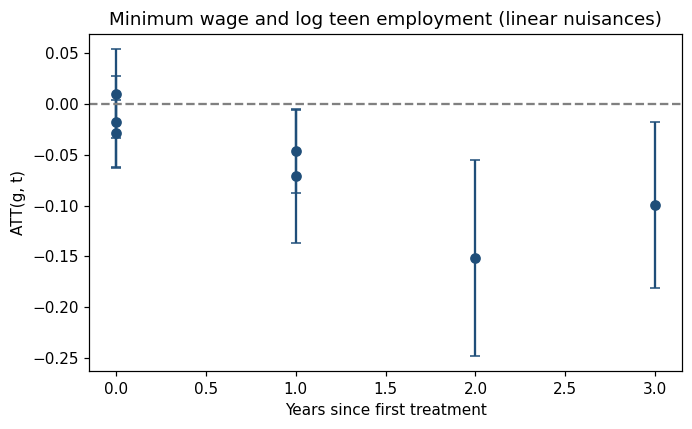

In [14]:
ref = att_b[att_b["learner"] == "linear"].copy()
ref["rel"] = ref["time"] - ref["G"]
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.errorbar(ref["rel"], ref["att"], yerr=1.96 * ref["se"], fmt="o", color="#1F4E79", capsize=3)
ax.axhline(0, color="grey", ls="--")
ax.set_xlabel("Years since first treatment")
ax.set_ylabel("ATT(g, t)")
ax.set_title("Minimum wage and log teen employment (linear nuisances)")
fig.tight_layout()


The aggregate is one number for the average post-treatment cell, with `lpop` as the covariate. Forests and boosting answer the same cells with different nuisances; small differences are expected.

### SHAP on one DiD slice

Group-time fits do not have a single `predict` surface. To show SHAP we take the 2004 cohort against never-treated counties, build $\Delta Y = \text{lemp}_{2004} - \text{lemp}_{2003}$, and fit `LinearDML` on `lpop` plus a second copy of the covariate so the CATE can vary. These values describe that slice, not the group-time table.


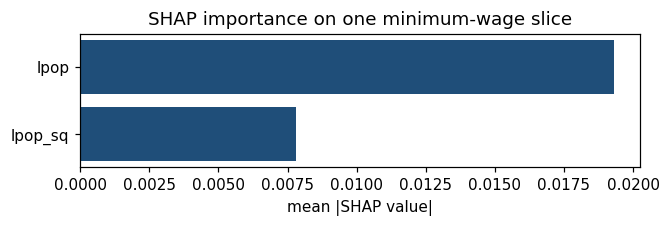

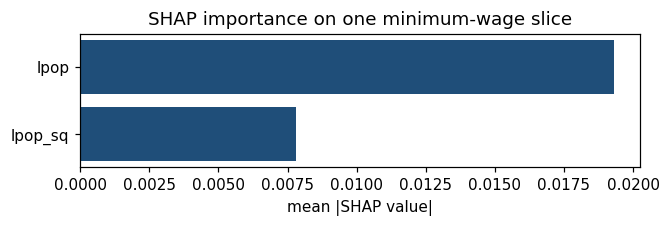

In [15]:
post = mpdta[mpdta["year"] == 2004][["countyreal", "lemp", "lpop", "first.treat"]]
pre = mpdta[mpdta["year"] == 2003][["countyreal", "lemp"]].rename(columns={"lemp": "lemp0"})
slice_s = post.merge(pre, on="countyreal")
slice_s = slice_s[slice_s["first.treat"].isin([0, 2004])].copy()
dy = (slice_s["lemp"] - slice_s["lemp0"]).to_numpy()
treat = (slice_s["first.treat"] == 2004).astype(int).to_numpy()
# Two columns so a linear CATE is not forced to a constant.
xs = np.column_stack([
    slice_s["lpop"].to_numpy(),
    (slice_s["lpop"] - slice_s["lpop"].mean()) ** 2,
])
ldml = LinearDML(discrete_treatment=True, n_splits=2, model_y="ridge", random_state=5)
ldml.fit(xs, treat, dy, feature_names=["lpop", "lpop_sq"])
explanation = explain_cate(ldml, xs, feature_names=["lpop", "lpop_sq"], max_samples=40, n_permutations=8, random_state=5)
explanation.plot_importance(title="SHAP importance on one minimum-wage slice")


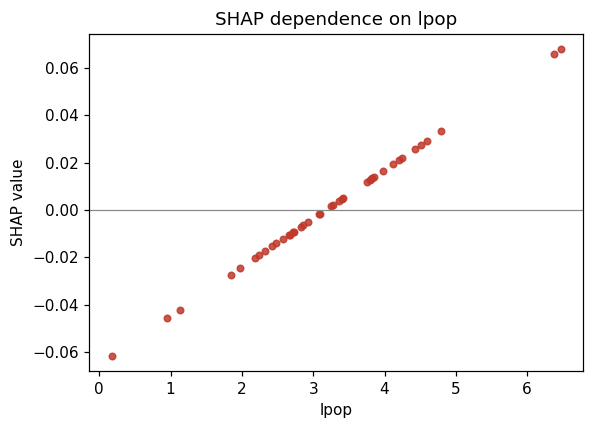

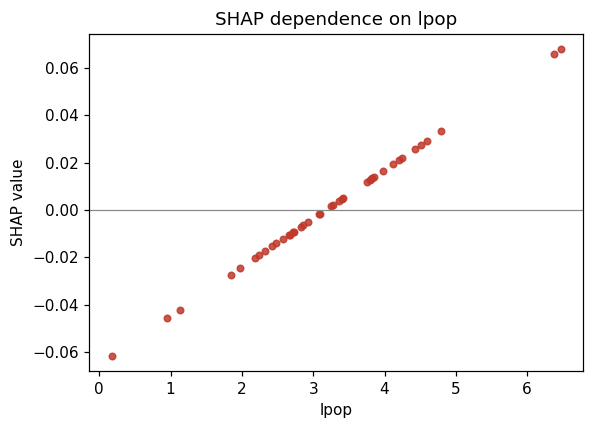

In [16]:
explanation.plot_dependence("lpop", title="SHAP dependence on lpop")


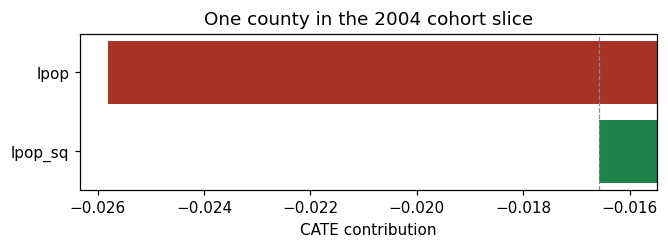

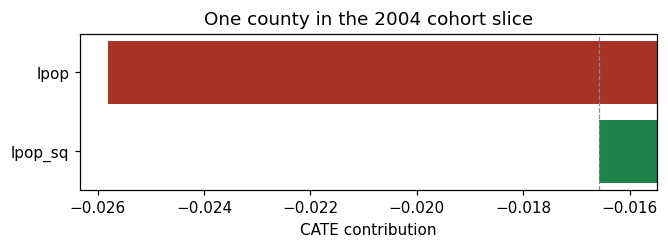

In [17]:
explanation.plot_waterfall(row=0, title="One county in the 2004 cohort slice")


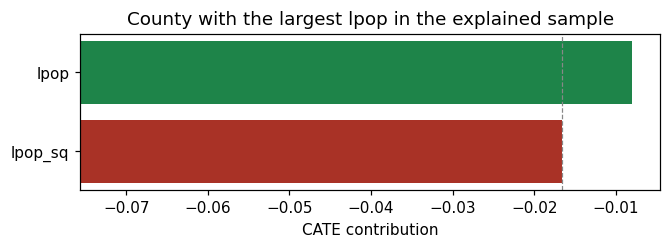

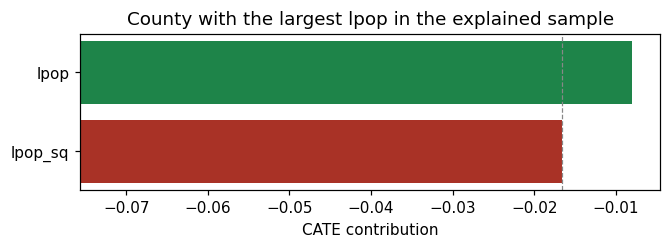

In [18]:
row = int(np.argmax(explanation.data[:, 0]))
explanation.plot_waterfall(row=row, title="County with the largest lpop in the explained sample")


## Summary

| Component | What we did |
|---|---|
| Data | Long panels with a cohort, a clock, an outcome, and covariates |
| Benchmark | `DifferenceInDifferences` on one 2×2 block |
| DML-DiD | Doubly robust score with linear, forest, and boosting nuisances |
| Diagnostics | Simple aggregates, pairwise ATT RMSE, nuisance RMSE and propensity accuracy |
| Real data | `Data/mpdta.csv`, minimum wages and log teen employment |
| SHAP | `LinearDML` on one first-differenced slice |

The orthogonal score lets the nuisances be nonlinear without handing the ATT a first-order bias from those fits. The linear nuisance is a good default; forests and boosting matter when the propensity or the outcome surface is clearly nonlinear.

## Resources

- Callaway, B., & Sant'Anna, P. H. C. (2021). Difference-in-differences with multiple time periods. *Journal of Econometrics*, 225(2), 200–230.
- Sant'Anna, P. H. C., & Zhao, J. (2020). Doubly robust difference-in-differences estimators. *Journal of Econometrics*, 219(1), 101–122.
- Chernozhukov, V., et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
